### Задание для курсовой работы (vo_PJ)

На основании предоставленных данных от химиков необходимо построить прогноз, позволяющий подобрать наиболее эффективное сочетание параметров для создания лекарственных препаратов.

Для этого требуется:

Проанализировать текущие параметры с использованием различных методов.

Научиться предсказывать их эффективность.

Создайте несколько максимально эффективных моделей для решения следующих задач:

Регрессия для IC50

Регрессия для CC50

Регрессия для SI

Классификация: превышает ли значение IC50 медианное значение выборки

Классификация: превышает ли значение CC50 медианное значение выборки

Классификация: превышает ли значение SI медианное значение выборки


Классификация: превышает ли значение SI значение 8

Сравните между собой полученные модели и их результаты, выполните анализ, обоснуйте выбор наиболее качественных решений.

#### Формат выполнения
Необходимо предоставить ссылку на GitHub-репозиторий, содержащий материалы достаточного (в соответствии с критериями) качества:

Код анализа представленных данных (EDA) — в отдельном файле.

Код построения моделей для каждой из задач — каждый файл должен соответствовать отдельной задаче.

Аналитический отчёт (в формате .pdf или .doc) с изложением результатов проделанной работы.

In [103]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [109]:
df = pd.read_excel(r'C:\IDE\2 семестр\Классическое МО\Курсовая работа\Данные_для_курсовои_Классическое_МО.xlsx', index_col=0)

In [12]:
df.head()

,"IC50, mM","CC50, mM",SI,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,6.239374,175.482382,28.125000,5.094096,5.094096,0.387225,0.387225,0.417362,42.928571,384.652,...,0,0,0,0,0,0,0,0,3,0
1,0.771831,5.402819,7.000000,3.961417,3.961417,0.533868,0.533868,0.462473,45.214286,388.684,...,0,0,0,0,0,0,0,0,3,0
2,223.808778,161.142320,0.720000,2.627117,2.627117,0.543231,0.543231,0.260923,42.187500,446.808,...,0,0,0,0,0,0,0,0,3,0
3,1.705624,107.855654,63.235294,5.097360,5.097360,0.390603,0.390603,0.377846,41.862069,398.679,...,0,0,0,0,0,0,0,0,4,0
4,107.131532,139.270991,1.300000,5.150510,5.150510,0.270476,0.270476,0.429038,36.514286,466.713,...,0,0,0,0,0,0,0,0,0,0


In [16]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Index: 1001 entries, 0 to 1000
Data columns (total 213 columns):
 #    Column                    Dtype  
---   ------                    -----  
 0    IC50, mM                  float64
 1    CC50, mM                  float64
 2    SI                        float64
 3    MaxAbsEStateIndex         float64
 4    MaxEStateIndex            float64
 5    MinAbsEStateIndex         float64
 6    MinEStateIndex            float64
 7    qed                       float64
 8    SPS                       float64
 9    MolWt                     float64
 10   HeavyAtomMolWt            float64
 11   ExactMolWt                float64
 12   NumValenceElectrons       int64  
 13   NumRadicalElectrons       int64  
 14   MaxPartialCharge          float64
 15   MinPartialCharge          float64
 16   MaxAbsPartialCharge       float64
 17   MinAbsPartialCharge       float64
 18   FpDensityMorgan1          float64
 19   FpDensityMorgan2          float64
 20   FpDensityMo

In [22]:
pd.set_option('display.max_rows', None)

print(df.isnull().sum())

IC50, mM                    0
CC50, mM                    0
SI                          0
MaxAbsEStateIndex           0
MaxEStateIndex              0
MinAbsEStateIndex           0
MinEStateIndex              0
qed                         0
SPS                         0
MolWt                       0
HeavyAtomMolWt              0
ExactMolWt                  0
NumValenceElectrons         0
NumRadicalElectrons         0
MaxPartialCharge            3
MinPartialCharge            3
MaxAbsPartialCharge         3
MinAbsPartialCharge         3
FpDensityMorgan1            0
FpDensityMorgan2            0
FpDensityMorgan3            0
BCUT2D_MWHI                 3
BCUT2D_MWLOW                3
BCUT2D_CHGHI                3
BCUT2D_CHGLO                3
BCUT2D_LOGPHI               3
BCUT2D_LOGPLOW              3
BCUT2D_MRHI                 3
BCUT2D_MRLOW                3
AvgIpc                      0
BalabanJ                    0
BertzCT                     0
Chi0                        0
Chi0n     

In [110]:
df = df.fillna(df.median(numeric_only=True))

In [38]:
print(df["IC50, mM"].describe())

count    1001.000000
mean      222.805156
std       402.169734
min         0.003517
25%        12.515396
50%        46.585183
75%       224.975928
max      4128.529377
Name: IC50, mM, dtype: float64


In [111]:
targets = df[['IC50, mM', 'CC50, mM', 'SI']]

X = df.drop(['IC50, mM', 'CC50, mM', 'SI'], axis=1)

In [112]:
y_reg_IC_50 = df['IC50, mM']

y_reg_IC_50 = np.log10(y_reg_IC_50)

'''y_reg_IC_50 = -np.log10(y_reg_IC_50 * 1e-3)'''

X_train_reg_IC_50, X_test_reg_IC_50, y_train_reg_IC_50, y_test_reg_IC_50 = train_test_split(X, y_reg_IC_50, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train_reg_IC_50.shape[0]} строк")
print(f"Тестовая выборка: {X_test_reg_IC_50.shape[0]} строк")

Обучающая выборка: 800 строк
Тестовая выборка: 201 строк


In [113]:
constant_cols = [col for col in X_train_reg_IC_50.columns if X[col].nunique(dropna=False) <= 1]

print("Константных признаков:", len(constant_cols))
print(constant_cols)

X_train_reg_IC_50 = X_train_reg_IC_50.drop(columns=constant_cols)
X_test_reg_IC_50 = X_test_reg_IC_50.drop(columns=constant_cols)
print("После удаления константных:", X_train_reg_IC_50.shape)

Константных признаков: 18
['NumRadicalElectrons', 'SMR_VSA8', 'SlogP_VSA9', 'fr_N_O', 'fr_SH', 'fr_azide', 'fr_barbitur', 'fr_benzodiazepine', 'fr_diazo', 'fr_dihydropyridine', 'fr_isocyan', 'fr_isothiocyan', 'fr_lactam', 'fr_nitroso', 'fr_phos_acid', 'fr_phos_ester', 'fr_prisulfonamd', 'fr_thiocyan']
После удаления константных: (800, 192)


In [114]:
fr_cols = [col for col in X_train_reg_IC_50.columns if col.startswith("fr_")]

print("Всего fr_* признаков:", len(fr_cols))

min_frac = 0.02
min_count = int(np.ceil(len(X) * min_frac))

rare_fr_cols = [col for col in fr_cols if (X_train_reg_IC_50[col] > 0).sum() < min_count]

print(f"Редких fr_* признаков (< {min_count} положительных случаев):", len(rare_fr_cols))
print(rare_fr_cols)

X_train_reg_IC_50 = X_train_reg_IC_50.drop(columns=rare_fr_cols)
X_test_reg_IC_50 = X_test_reg_IC_50.drop(columns=rare_fr_cols)

print("После удаления редких fr_*:", X_train_reg_IC_50.shape)

Всего fr_* признаков: 70
Редких fr_* признаков (< 21 положительных случаев): 23
['fr_ArN', 'fr_Ar_COO', 'fr_HOCCN', 'fr_aldehyde', 'fr_alkyl_carbamate', 'fr_amidine', 'fr_azo', 'fr_epoxide', 'fr_guanido', 'fr_hdrzine', 'fr_nitrile', 'fr_nitro', 'fr_nitro_arom', 'fr_nitro_arom_nonortho', 'fr_oxazole', 'fr_oxime', 'fr_piperzine', 'fr_priamide', 'fr_sulfonamd', 'fr_sulfone', 'fr_term_acetylene', 'fr_tetrazole', 'fr_urea']
После удаления редких fr_*: (800, 169)


In [119]:
import seaborn as sns
import matplotlib.pyplot as plt

# Допустим, у вас есть DataFrame df
corr_matrix = X_train_reg_IC_50.corr()
pairs = corr_matrix.unstack().sort_values(ascending=False)
pairs = pairs[pairs != 1.0]
print("Топ сильных связей:")
print(pairs.head(50))

Топ сильных связей:
ExactMolWt              MolWt                     0.999999
MolWt                   ExactMolWt                0.999999
Chi1                    HeavyAtomCount            0.998777
HeavyAtomCount          Chi1                      0.998777
MolWt                   HeavyAtomMolWt            0.997021
HeavyAtomMolWt          MolWt                     0.997021
ExactMolWt              HeavyAtomMolWt            0.996992
HeavyAtomMolWt          ExactMolWt                0.996992
HeavyAtomCount          Chi0                      0.996104
Chi0                    HeavyAtomCount            0.996104
                        NumValenceElectrons       0.995075
NumValenceElectrons     Chi0                      0.995075
LabuteASA               HeavyAtomCount            0.994629
HeavyAtomCount          LabuteASA                 0.994629
LabuteASA               Chi1                      0.993155
Chi1                    LabuteASA                 0.993155
Chi0v                   Chi0n       

In [123]:
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
import numpy as np

model = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

# R2
r2_scores = cross_val_score(
    model,
    X_train_reg_IC_50,
    y_train_reg_IC_50,
    scoring="r2",
    cv=cv,
    n_jobs=-1
)

# MAE (с минусом!)
mae_scores = cross_val_score(
    model,
    X_train_reg_IC_50,
    y_train_reg_IC_50,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

print("CV R2:", np.mean(r2_scores), "±", np.std(r2_scores))
print("CV MAE:", -np.mean(mae_scores), "±", np.std(mae_scores))

CV R2: 0.43340216758013794 ± 0.059516474176780625
CV MAE: 0.5400530894482825 ± 0.04147933516148115


In [125]:
from sklearn.metrics import r2_score, mean_absolute_error

model.fit(X_train_reg_IC_50, y_train_reg_IC_50)

y_pred = model.predict(X_test_reg_IC_50)

print("TEST R2:", r2_score(y_test_reg_IC_50, y_pred))
print("TEST MAE:", mean_absolute_error(y_test_reg_IC_50, y_pred))

TEST R2: 0.5069414884411974
TEST MAE: 0.5411138778123875


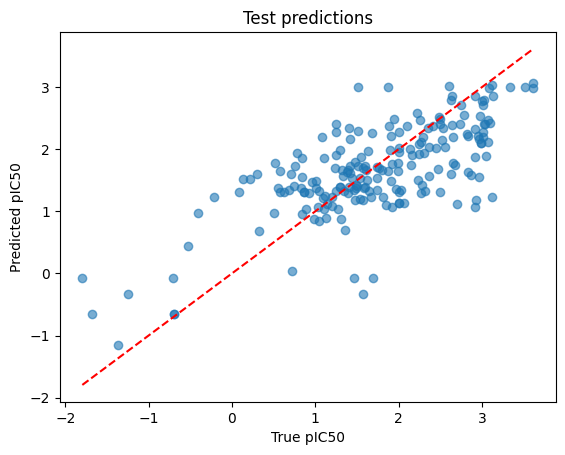

In [127]:
import matplotlib.pyplot as plt

plt.scatter(y_test_reg_IC_50, y_pred, alpha=0.6)
plt.xlabel("True pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Test predictions")
plt.plot([y_test_reg_IC_50.min(), y_test_reg_IC_50.max()],
         [y_test_reg_IC_50.min(), y_test_reg_IC_50.max()],
         "r--")
plt.show()

In [128]:
import pandas as pd

importances = model.feature_importances_

feat_imp = pd.DataFrame({
    "feature": X_train_reg_IC_50.columns,
    "importance": importances
}).sort_values("importance", ascending=False)

print(feat_imp.head(20))

               feature  importance
100        VSA_EState8    0.130028
98         VSA_EState6    0.113801
96         VSA_EState4    0.031780
36               Chi3n    0.028600
24        BCUT2D_MRLOW    0.021309
25              AvgIpc    0.020963
4                  qed    0.019362
19        BCUT2D_CHGHI    0.017095
120            MolLogP    0.016538
18        BCUT2D_MWLOW    0.015786
84         EState_VSA2    0.015720
14    FpDensityMorgan1    0.015412
97         VSA_EState5    0.014620
146        fr_bicyclic    0.014299
95         VSA_EState3    0.014008
87         EState_VSA5    0.013286
16    FpDensityMorgan3    0.013220
57           PEOE_VSA7    0.012846
2    MinAbsEStateIndex    0.012563
46           PEOE_VSA1    0.012550


In [129]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model,
    X_test_reg_IC_50,
    y_test_reg_IC_50,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_imp = pd.DataFrame({
    "feature": X_test_reg_IC_50.columns,
    "importance": perm.importances_mean
}).sort_values("importance", ascending=False)

print(perm_imp.head(20))

                 feature  importance
100          VSA_EState8    0.203061
98           VSA_EState6    0.190369
96           VSA_EState4    0.030620
120              MolLogP    0.007981
36                 Chi3n    0.007870
24          BCUT2D_MRLOW    0.006884
14      FpDensityMorgan1    0.006295
11      MinPartialCharge    0.005721
46             PEOE_VSA1    0.004456
42                Kappa1    0.004353
104            NHOHCount    0.004260
15      FpDensityMorgan2    0.004094
12   MaxAbsPartialCharge    0.003031
69            SlogP_VSA1    0.002958
19          BCUT2D_CHGHI    0.002702
113           NumHDonors    0.002109
57             PEOE_VSA7    0.002044
43                Kappa2    0.002019
82          EState_VSA10    0.001909
53             PEOE_VSA3    0.001820


In [120]:
model = RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train_reg_IC_50, y_train_reg_IC_50)

y_pred = model.predict(X_test_reg_IC_50)

In [122]:
mae = mean_absolute_error(y_test_reg_IC_50, y_pred)
mse = mean_squared_error(y_test_reg_IC_50, y_pred)
rmse = root_mean_squared_error(y_test_reg_IC_50, y_pred)  
r2 = r2_score(y_test_reg_IC_50, y_pred)

print(f"MAE (Средняя абсолютная ошибка): {mae:.2f}")
print(f"RMSE (Среднеквадратичная ошибка): {rmse:.2f}")
print(f"R^2 (Коэффициент детерминации): {r2:.2f}")

MAE (Средняя абсолютная ошибка): 0.54
RMSE (Среднеквадратичная ошибка): 0.71
R^2 (Коэффициент детерминации): 0.50
